# LlamaParse test on the annual report

Notebook 03 found that local Unstructured `hi_res` duplicates lines, splits a table's last column into loose numbers,
turns diagrams into OCR fragments and reads checkmarks as `ü`. This notebook parses the same kind of pages with
[LlamaParse](https://developers.llamaindex.ai/llamaparse/parse/getting_started) (`agentic` tier) to see whether it does better.

Seven pages of `2026-Annual-Report-Web.pdf` are parsed:

| Page | What it tests |
|---|---|
| 4, 8 | Wide spreads with large diagrams |
| 13 | Shareholder letter in three columns |
| 26 | Director table with checkmarks |
| 128 | Broken font: the PDF text layer is garbled |
| 139 | Consolidated Statements of Income |
| 142 | Landscape equity table |

The `agentic` tier costs 10 credits a page, so one run costs about 70 credits. The result is cached in
`notebooks/llamaparse_output/`, and the parse only runs again if that cache is deleted.

In [1]:
import html
import json
import re
import sys
from collections import Counter
from pathlib import Path

import httpx
from IPython.display import HTML, display
from PIL import Image
from pypdf import PdfReader

PROJECT_ROOT = Path.cwd().parent  # this notebook lives in notebooks/
sys.path.insert(0, str(PROJECT_ROOT))

from multimodal_rag import config  # noqa: F401  loads .env, including LLAMA_CLOUD_API_KEY

REPORT_PATH = PROJECT_ROOT / "2026-Annual-Report-Web.pdf"
OUTPUT_DIRECTORY = PROJECT_ROOT / "notebooks" / "llamaparse_output"
RESULT_PATH = OUTPUT_DIRECTORY / "sample_result.json"
IMAGE_DIRECTORY = OUTPUT_DIRECTORY / "images"

TEST_PAGES = [4, 8, 13, 26, 128, 139, 142]

## 1. Parse the pages, or load the cached result

Settings:

- `tier="agentic"`: a vision model reads each page.
- `page_ranges.target_pages`: only the test pages. Page numbers in the result are the report's own page numbers.
- `output_tables_as_markdown: False`: tables come back as HTML, which keeps merged header cells.
- `images_to_save: ["layout", "screenshot"]`: cropped figures and tables, plus a render of each page.

Image download links expire, so the images are downloaded right after parsing.

In [2]:
def parse_test_pages():
    from llama_cloud import LlamaCloud

    client = LlamaCloud()  # reads LLAMA_CLOUD_API_KEY from the environment
    file = client.files.create(file=str(REPORT_PATH), purpose="parse")
    result = client.parsing.parse(
        file_id=file.id,
        tier="agentic",
        version="latest",
        page_ranges={"target_pages": ",".join(str(page) for page in TEST_PAGES)},
        output_options={
            "markdown": {"tables": {"output_tables_as_markdown": False}},
            "images_to_save": ["layout", "screenshot"],
        },
        expand=["markdown", "items", "images_content_metadata", "metadata"],
    )
    data = result.model_dump(mode="json")

    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    RESULT_PATH.write_text(json.dumps(data, indent=1))
    IMAGE_DIRECTORY.mkdir(exist_ok=True)
    for image in data["images_content_metadata"]["images"]:
        response = httpx.get(image["presigned_url"], timeout=60)
        response.raise_for_status()
        (IMAGE_DIRECTORY / image["filename"]).write_bytes(response.content)
    return data


if RESULT_PATH.exists():
    result = json.loads(RESULT_PATH.read_text())
    print(f"Loaded the cached result from {RESULT_PATH.relative_to(PROJECT_ROOT)}")
else:
    result = parse_test_pages()
    print("Parsed the test pages with LlamaParse")

print(f"Job {result['job']['id']}: {result['job']['status']}, tier {result['job']['tier']}")
markdown_by_page = {page["page_number"]: page["markdown"] for page in result["markdown"]["pages"]}
for page in result["metadata"]["pages"]:
    number = page["page_number"]
    print(f"page {number:3}: {len(markdown_by_page[number]):5} characters of markdown, "
          f"printed page number {page['printed_page_number']!r}, confidence {page['confidence']}")

Loaded the cached result from notebooks/llamaparse_output/sample_result.json
Job pjb-gt9qv0jmqt15kqr79wsmwkxm8zpi: COMPLETED, tier agentic
page   4:   795 characters of markdown, printed page number None, confidence 0.904
page   8:  1268 characters of markdown, printed page number None, confidence 0.711
page  13:  4099 characters of markdown, printed page number None, confidence 0.998
page  26:  5055 characters of markdown, printed page number None, confidence 0.864
page 128:  3542 characters of markdown, printed page number None, confidence 0.509
page 139:  2024 characters of markdown, printed page number None, confidence 0.429
page 142:  3971 characters of markdown, printed page number None, confidence 0.775


## 2. The markdown, page by page

This is what would be chunked and embedded. Tables are HTML inside the markdown.

In [3]:
for number in TEST_PAGES:
    print(f"==================== page {number}")
    print(markdown_by_page[number])
    print()

==================== page 4
## **AI Is Driving the Largest Infrastructure Buildout in Human History**

**Data centers are becoming AI factories.**

Land, power, cooling, networking, and systems must scale in parallel.
Every company will use AI. Every country will build AI infrastructure.
This is the next industrial revolution. We are only a few hundred billion dollars into it. Trillions more still need to be built.

image: infographic showing the evolution of DSX technology and its integration into data center infrastructure

**Reference Designs, Best Practices, Methodologies**

**Rubin DSX Reference Designs**

**DSX Ecosystem**

**Omniverse DSX Blueprint**

**DSX Max-Q**

**DSX Flex**

**DSX Exchange**

**DSX Sim**

**DSX Libraries, APIs, Software**

**Chips, Systems, Facilities**

**Power**

**Liquid Cooling**

==================== page 8
## **Agentic AI Enters Production**

**AI now perceives, reasons, plans, and acts.**

Agentic systems break complex problems into steps. They evalu

## 3. Numbers check

A vision model can misread or invent a digit. This PDF has a real text layer (except page 128), so every number in the
markdown should also appear in that page's text layer. Numbers are compared without commas, `$` and `%`.
Page 128 is skipped because its text layer is garbled.

In [4]:
reader = PdfReader(REPORT_PATH)
NUMBER = re.compile(r"\d[\d,]*(?:\.\d+)?")


def numbers_in(text):
    text = html.unescape(text)  # so an entity like &#x26; (&) is not read as the number 26
    return {match.replace(",", "") for match in NUMBER.findall(text) if len(match.replace(",", "")) >= 2}


for number in TEST_PAGES:
    if number == 128:
        print(f"page {number:3}: skipped, the text layer is garbled")
        continue
    in_markdown = numbers_in(markdown_by_page[number])
    in_pdf = numbers_in(reader.pages[number - 1].extract_text())
    missing = sorted(in_markdown - in_pdf)
    print(f"page {number:3}: {len(in_markdown):3} numbers in the markdown, {len(missing)} not in the PDF text {missing}")

page   4:   0 numbers in the markdown, 0 not in the PDF text []
page   8:   0 numbers in the markdown, 0 not in the PDF text []
page  13:   2 numbers in the markdown, 0 not in the PDF text []
page  26:  18 numbers in the markdown, 0 not in the PDF text []
page 128: skipped, the text layer is garbled
page 139:  60 numbers in the markdown, 0 not in the PDF text []
page 142:  65 numbers in the markdown, 0 not in the PDF text []


## 4. Tables, rendered

The two financial statements as LlamaParse returned them. Compare with the page images in section 5.

In [5]:
for number in [139, 142]:
    tables = re.findall(r"<table>.*?</table>", markdown_by_page[number], flags=re.DOTALL)
    print(f"page {number}: {len(tables)} table(s)")
    for table in tables:
        display(HTML(table))

page 139: 1 table(s)


page 142: 1 table(s)


## 5. Images

`layout` images are figures and tables cropped from the page. `screenshot` images are whole pages.
File names carry the page number, for example `page_4_image_1_v2.jpg`.

Counter({'layout': 10, 'screenshot': 7})
page_4_image_2_v2.jpg  box on the page: {'h': 79, 'w': 387, 'x': 109, 'y': 361}


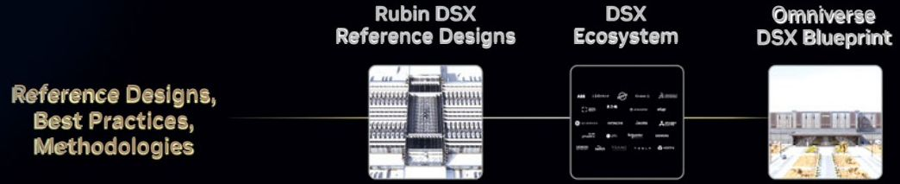

page_4_image_1_v2.jpg  box on the page: {'h': 356, 'w': 994, 'x': 96, 'y': 362}


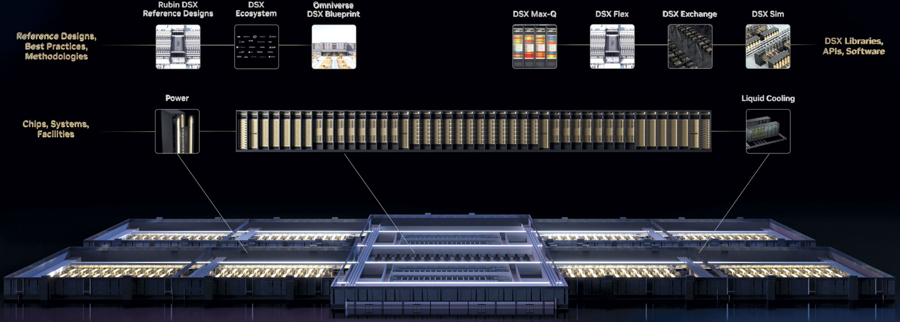

page_8_chart_1_v2.jpg  box on the page: {'h': 295, 'w': 956, 'x': 70, 'y': 397}


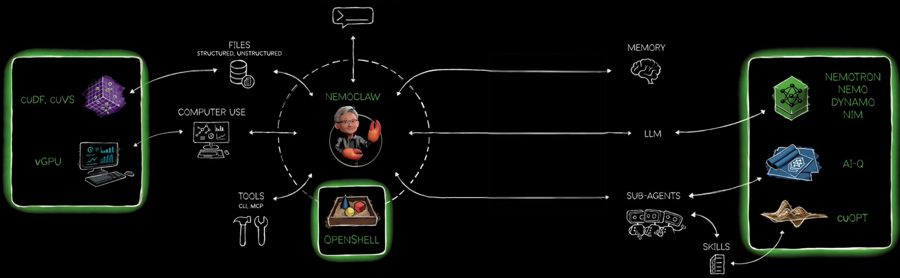

page_26_table_1_v2.jpg  box on the page: {'h': 183, 'w': 516, 'x': 39, 'y': 67}


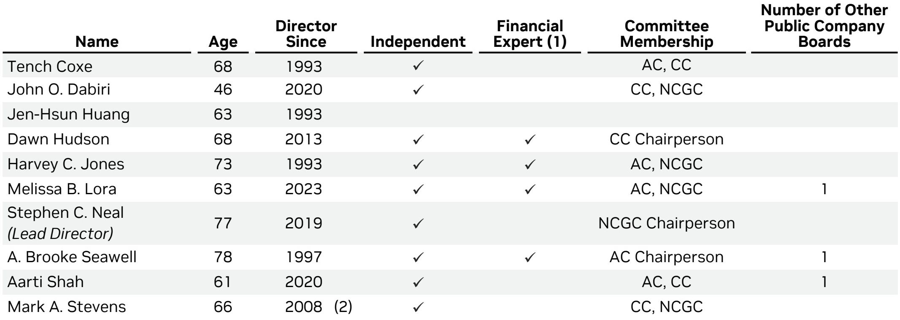

page_26_table_2_v2.jpg  box on the page: {'h': 199, 'w': 509, 'x': 42, 'y': 516}


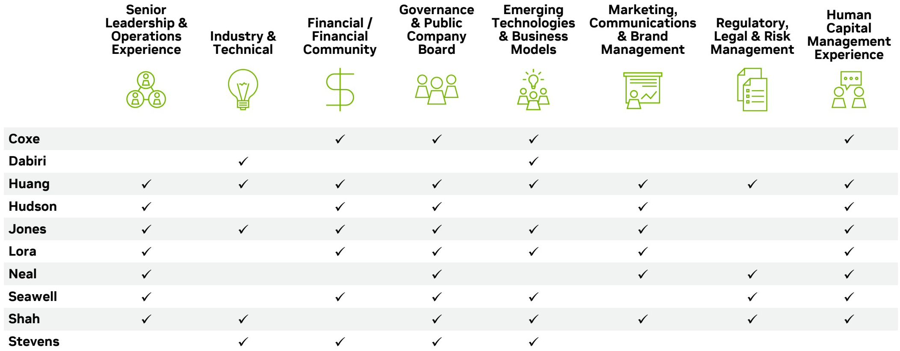

page_128_table_3_v2.jpg  box on the page: {'h': 99, 'w': 515, 'x': 39, 'y': 370}


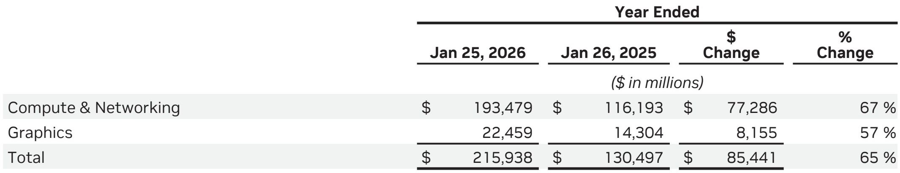

page_128_table_2_v2.jpg  box on the page: {'h': 99, 'w': 515, 'x': 39, 'y': 498}


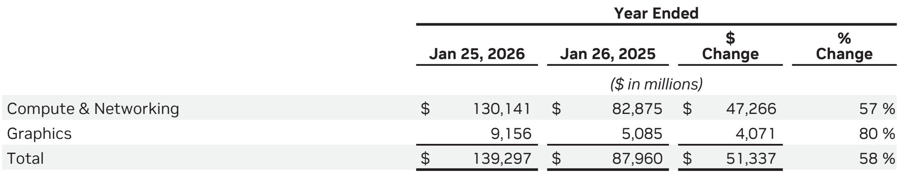

page_128_table_1_v2.jpg  box on the page: {'h': 254, 'w': 515, 'x': 39, 'y': 67}


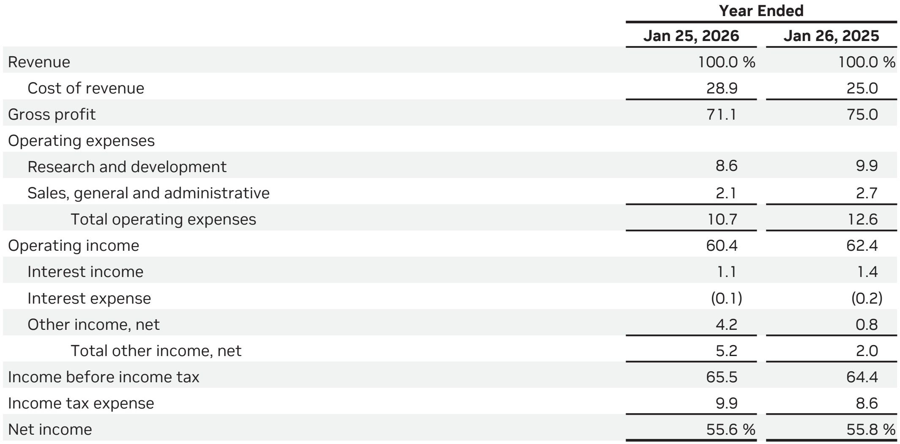

page_139_table_1_v2.jpg  box on the page: {'h': 362, 'w': 507, 'x': 43, 'y': 72}


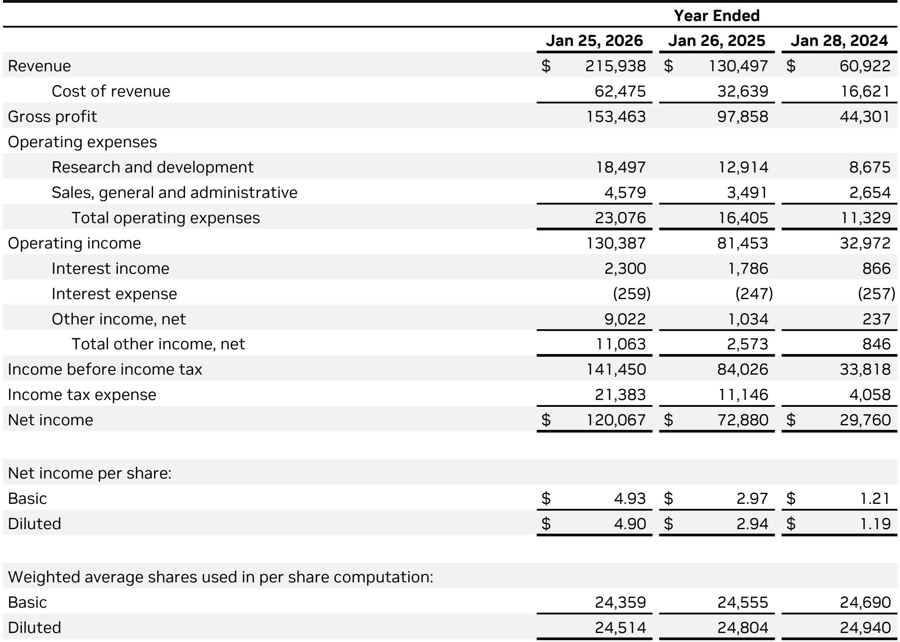

page_142_table_1_v2.jpg  box on the page: {'h': 396, 'w': 683, 'x': 46, 'y': 58}


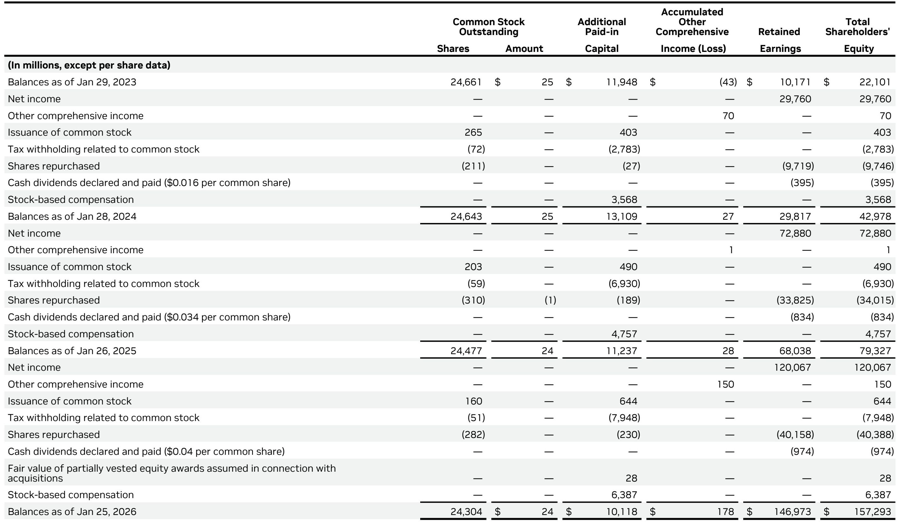

In [6]:
images = result["images_content_metadata"]["images"]
print(Counter(image["category"] for image in images))

for image in images:
    if image["category"] != "layout":
        continue
    picture = Image.open(IMAGE_DIRECTORY / image["filename"])
    picture.thumbnail((900, 900))
    print(f"{image['filename']}  box on the page: {image['bbox']}")
    display(picture)

The spreads as whole pages, to compare with the crops above:

page 4


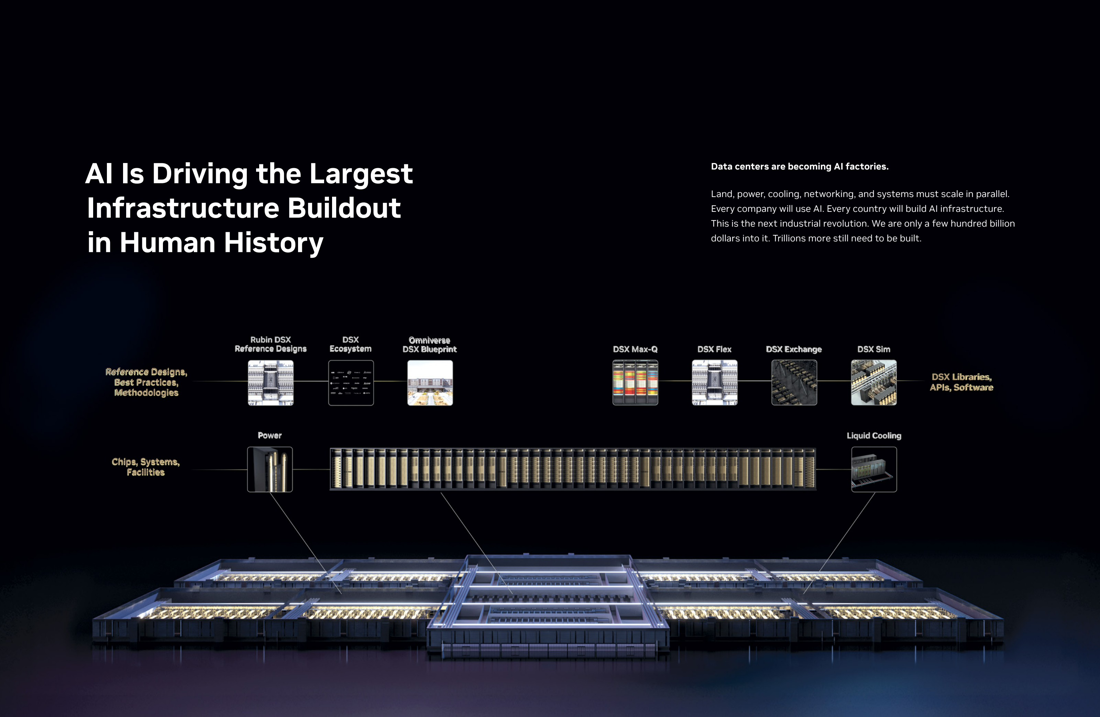

page 8


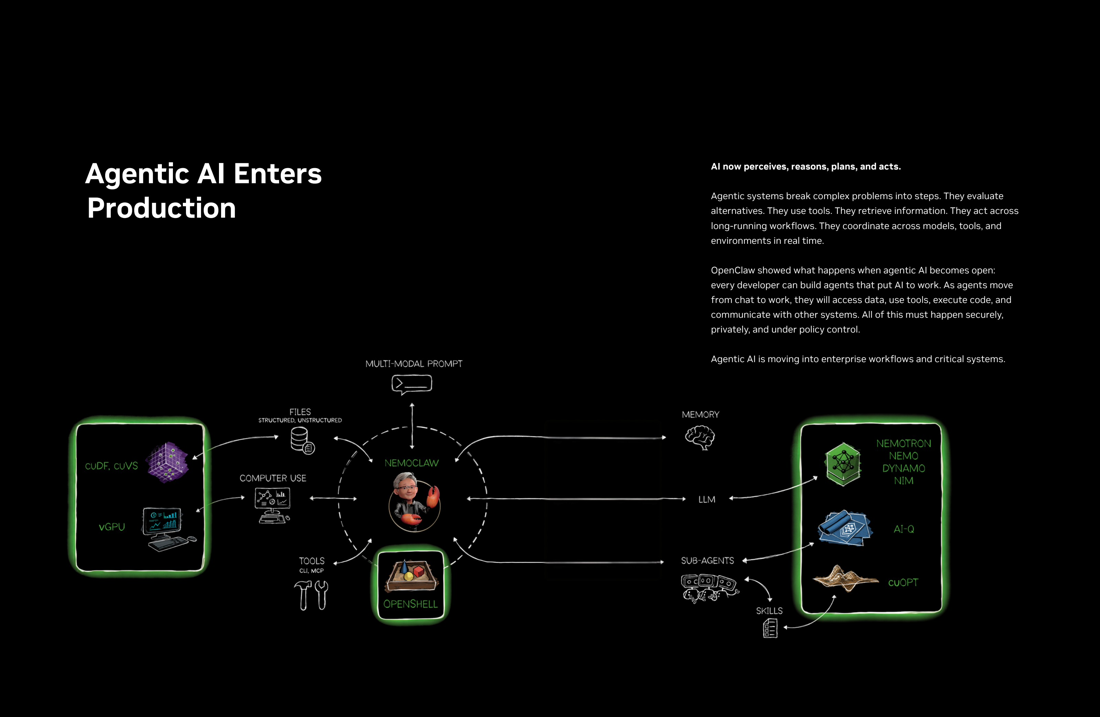

In [7]:
for number in [4, 8]:
    picture = Image.open(IMAGE_DIRECTORY / f"page_{number}.jpg")
    picture.thumbnail((1100, 1100))
    print(f"page {number}")
    display(picture)

## 6. Duplicated lines and stray characters

Notebook 03 found many lines output twice and checkmarks read as `ü`. Count both here.

In [8]:
for number in TEST_PAGES:
    # Table markup is skipped: two tables on one page can rightly share the same header rows
    lines = [line.strip() for line in markdown_by_page[number].splitlines()
             if len(line.strip()) > 20 and not line.strip().startswith("<")]
    repeated = [line for line, count in Counter(lines).items() if count > 1]
    print(f"page {number:3}: {len(repeated)} repeated line(s), "
          f"{markdown_by_page[number].count('ü')} 'ü', {markdown_by_page[number].count('✓')} '✓'")

page   4: 0 repeated line(s), 0 'ü', 0 '✓'
page   8: 0 repeated line(s), 0 'ü', 0 '✓'
page  13: 0 repeated line(s), 0 'ü', 0 '✓'
page  26: 0 repeated line(s), 0 'ü', 67 '✓'
page 128: 0 repeated line(s), 0 'ü', 0 '✓'
page 139: 0 repeated line(s), 0 'ü', 0 '✓'
page 142: 0 repeated line(s), 0 'ü', 0 '✓'


## Findings

**LlamaParse fixes every problem notebook 03 found with local Unstructured.**

| Problem with local Unstructured | LlamaParse |
|---|---|
| Lines output twice | No repeated lines on any page |
| A table's last column split into loose numbers (pages 139, 142) | Both tables complete, with every column and row label in place |
| Diagrams on spreads turned into OCR fragments (pages 4, 8) | Page 4's diagram is cropped as one image with its labels listed; page 8's is cropped and also rewritten as a Mermaid flowchart with its connections |
| Checkmarks read as `ü` (page 26) | 67 real `✓` marks in the right cells |
| Garbled text layer on page 128 | Read correctly from the page image |

- **Numbers:** every number in the markdown of pages 13, 26, 139 and 142 also appears in the PDF text layer (125 on the two financial statements alone). No misread or invented digits.
- **Speed and cost:** 12 seconds for the seven pages, against 67 seconds for local `hi_res` on eight. 70 credits, so the whole report is about 1,750 credits in `agentic`.
- **Images:** the `layout` crops are what the answering model should see: whole diagrams and tables, cut cleanly from the spread background. Their file names carry the page number.
- **Weak spots:**
  - Page 4's diagram gets only a one-line caption in the markdown. The crop is good, so the image description step (or the answering model) would still see it.
  - `page_4_image_2` is a smaller crop that overlaps `page_4_image_1`.
  - `confidence` varies (0.43 on page 139, which is perfect), so it is not a useful quality signal here.
  - `printed_page_number` is empty because `extract_printed_page_number` was not requested. Turn it on to cite the page numbers printed in the report.

**Next:** chunk the markdown (each page is already a natural unit), keep the `layout` crops as each chunk's images, and run the test questions against a store built this way.